# Fraunhofer Diffraction -- Double Slit

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-06.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        importlib.invalidate_caches()  # make the freshly installed package importable
        try:  # matplotlib caches its backend list on first use; refresh it so no restart is needed
            from matplotlib.backends.registry import backend_registry
            backend_registry._clear()
        except Exception:
            pass
    import ipympl  # noqa: F401
    from google.colab import output
    output.enable_custom_widget_manager()
    print("Colab setup done. If a %matplotlib widget cell still errors, use Runtime > Restart session, then Run all.")

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
d1 = 250              # slit separation in microns


numpointsx1 = 512
x1aperture = np.linspace(-400,400,num=numpointsx1) # points in the aperture
y1aperture = np.zeros_like(x1aperture)  # y-coordinates (for plotting baseline)

slit_width1 = 4
mask1 = (np.abs(x1aperture - d1/2) < slit_width1/2) | (np.abs(x1aperture + d1/2) < slit_width1/2)
aperture1_density = np.where(mask1, 1.0, 0.0)
aperture1_2d = np.tile(aperture1_density, (100, 1))

x1 = np.linspace(-1e5,1e5,num=numpointsx1) # points on the screen
intensity1 = (np.cos(np.pi*d1/wavelength1*x1/np.sqrt(x1**2+L1**2)))**2

# Expand the 1D intensity array into 2D for image plotting
# We tile it vertically to give it height
intensity1_2d = np.tile(intensity1, (100, 1))

## Plot

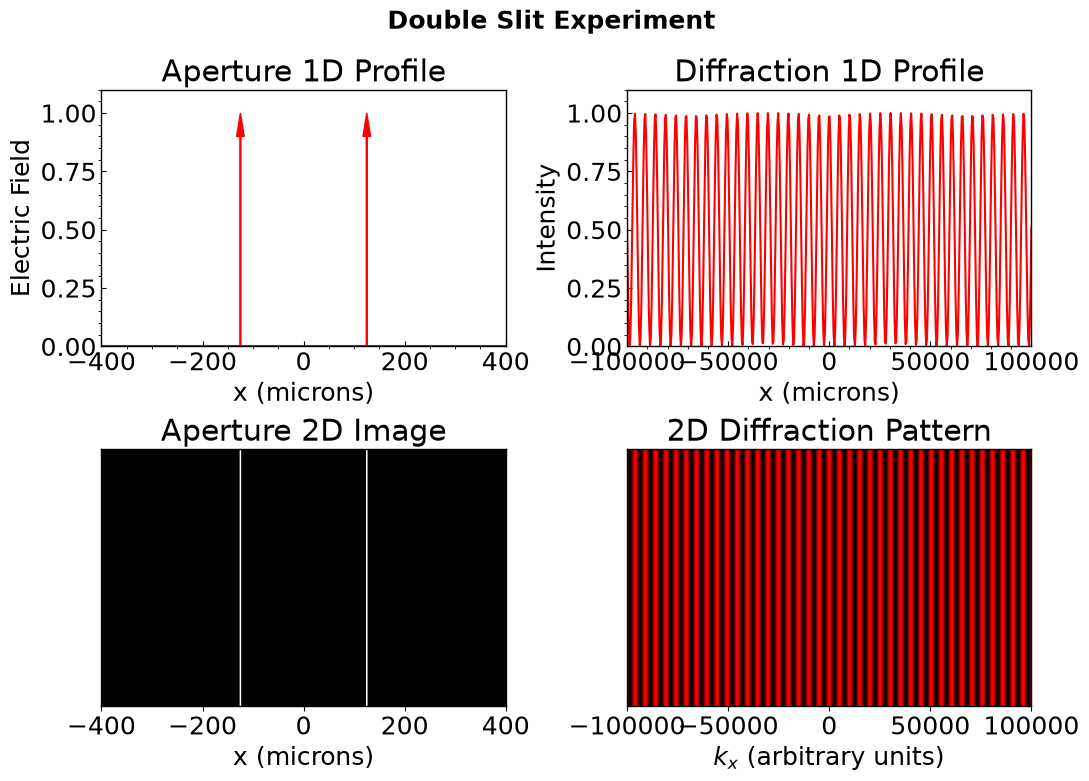

In [4]:
# --- 4. Plotting ---
# Create a 2x2 grid
fig, axs = plt.subplots(2, 2, figsize=(12, 8), 
                        gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.4, 'wspace': 0.3})
fig.suptitle("Double Slit Experiment", fontsize=18, fontweight='bold')

# --- Top Left: Aperture 1D Plot ---
ax11 = axs[0, 0]
ax11.plot(x1aperture, y1aperture, color='r', linewidth=1.5)
# Add arrows to represent the delta functions/slits
arrow_settings = dict(head_width=15, head_length=0.1, fc='red', ec='red', width=2)
ax11.arrow(-d1/2, 0, 0, 1, length_includes_head=True, **arrow_settings)
ax11.arrow(d1/2, 0, 0, 1, length_includes_head=True, **arrow_settings)

ax11.set_xlim(-400, 400)
ax11.set_ylim(0, 1.1)
ax11.set_xlabel("x (microns)")
ax11.set_ylabel("Electric Field")
ax11.set_title("Aperture 1D Profile")
ax11.minorticks_on()
ax11.tick_params(direction="in")

# --- Bottom Left: Aperture 2D Image ---
ax21 = axs[1, 0]
ax21.imshow(aperture1_2d, extent=[-400, 400, -1, 1], aspect='auto', cmap='gray', vmin=0, vmax=1)
ax21.set_xlabel("x (microns)")
ax21.set_yticks([]) # Hide y ticks
ax21.set_title("Aperture 2D Image")

# --- Top Right: Diffraction 1D Plot ---
ax12 = axs[0, 1]
ax12.plot(x1, intensity1, color='red', linewidth=1.5)
ax12.set_xlim(-1e5, 1e5)
ax12.set_ylim(0, 1.1)
ax12.set_xlabel("x (microns)")
ax12.set_ylabel("Intensity")
ax12.set_title("Diffraction 1D Profile")
ax12.minorticks_on()
ax12.tick_params(direction="in")

# --- Bottom Right: Diffraction 2D Image ---
ax22 = axs[1, 1]
# Custom Laser Red Colormap
colors = [(0, 0, 0), (1, 0, 0)] # Black to Red
laser_cmap = LinearSegmentedColormap.from_list("laser_red", colors)

ax22.imshow(intensity1_2d, extent=[-1e5, 1e5, -1, 1], aspect='auto', cmap=laser_cmap, vmin=0, vmax=1)
ax22.set_xlabel(r"$k_x$ (arbitrary units)")
ax22.set_yticks([]) # Hide y ticks
ax22.set_title("2D Diffraction Pattern")

plt.show()

## Animation

In [5]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import ipywidgets as widgets
from IPython.display import display

# --- 1. Global Setup ---
plt.rcParams.update({'font.size': 10, 'lines.linewidth': 2.0})

# Constants
L2 = 2 * 10**6       # Screen distance (microns)
X_SCREEN_MAX = 1e5   # Screen range
X_AP_MAX = 400       # Aperture range
NUM_POINTS = 1000    
SLIT_WIDTH = 4       

# Global Data Arrays
x_ap = np.linspace(-X_AP_MAX, X_AP_MAX, NUM_POINTS)
x_screen = np.linspace(-X_SCREEN_MAX, X_SCREEN_MAX, NUM_POINTS)
y_zero = np.zeros_like(x_ap)

# Helper: Wavelength to RGB
def get_color(wl_um):
    wl_nm = wl_um * 1000
    if 380 <= wl_nm <= 440: R,G,B = -(wl_nm - 440)/(60), 0.0, 1.0
    elif 440 < wl_nm <= 490: R,G,B = 0.0, (wl_nm - 440)/(50), 1.0
    elif 490 < wl_nm <= 510: R,G,B = 0.0, 1.0, -(wl_nm - 510)/(20)
    elif 510 < wl_nm <= 580: R,G,B = (wl_nm - 510)/(70), 1.0, 0.0
    elif 580 < wl_nm <= 645: R,G,B = 1.0, -(wl_nm - 645)/(65), 0.0
    elif 645 < wl_nm <= 750: R,G,B = 1.0, 0.0, 0.0
    else: R,G,B = 0.2, 0.2, 0.2
    return (R, G, B)

# --- 2. Create Figure ---
fig2, axs2 = plt.subplots(2, 2, figsize=(9, 6), 
                        gridspec_kw={'height_ratios': [1, 1], 'hspace': 0.4, 'wspace': 0.3})
fig2.canvas.header_visible = False
fig2.canvas.footer_visible = False
fig2.suptitle("Double Slit Experiment", fontsize=14, fontweight='bold')

# --- 3. Initial Plotting ---

# [Top Left] Aperture 1D Profile
ax2 = axs2[0, 0]
ax2.plot(x_ap, y_zero, color='k', linewidth=1, alpha=0.3) # Baseline

# Initialize Arrows (Annotation objects)
# Note: We store these in variables so we can update them later
# xy is the arrow tip, xytext is the arrow tail
arrow_props = dict(facecolor='red', edgecolor='red', width=3, headwidth=10, shrink=0.0)
arrow_L = ax2.annotate('', xy=(-125, 1), xytext=(-125, 0), arrowprops=arrow_props)
arrow_R = ax2.annotate('', xy=(125, 1), xytext=(125, 0), arrowprops=arrow_props)

ax2.set_xlim(-400, 400); ax2.set_ylim(0, 1.1)
ax2.set_title("Aperture 1D Profile"); ax2.set_ylabel("Electric Field")
ax2.minorticks_on(); ax2.tick_params(direction="in")

# [Bottom Left] Aperture 2D Image
ax4 = axs2[1, 0]
img_ap = ax4.imshow(np.zeros((10, NUM_POINTS)), extent=[-400, 400, -1, 1], 
                     aspect='auto', cmap='gray', vmin=0, vmax=1)
ax4.set_yticks([]); ax4.set_xlabel("x (microns)"); ax4.set_title("Aperture 2D Image")

# [Top Right] Diffraction 1D Profile
ax3 = axs2[0, 1]
line_diff, = ax3.plot(x_screen, np.zeros_like(x_screen), color='red', linewidth=1.5)
ax3.set_xlim(-1e5, 1e5); ax3.set_ylim(0, 1.1)
ax3.set_title("Diffraction 1D Profile"); ax3.set_ylabel("Intensity")
ax3.minorticks_on(); ax3.tick_params(direction="in")

# [Bottom Right] Diffraction 2D Pattern
ax5 = axs2[1, 1]
initial_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), (1,0,0)])
img_diff = ax5.imshow(np.zeros((10, NUM_POINTS)), extent=[-1e5, 1e5, -1, 1], 
                       aspect='auto', cmap=initial_cmap, vmin=0, vmax=1)
ax5.set_yticks([]); ax5.set_xlabel(r"$k_x$ (arbitrary units)"); ax5.set_title("Diffraction Pattern")


# --- 4. Update Function ---
def update_plots(d_val, w_val):
    # A. Physics
    color = get_color(w_val)
    
    # Diffraction I = cos^2(...)
    theta_term = x_screen / np.sqrt(x_screen**2 + L2**2)
    beta = (np.pi * d_val * theta_term) / w_val
    intensity = np.cos(beta)**2
    
    # Aperture Mask
    mask = (np.abs(x_ap - d_val/2) < SLIT_WIDTH/2) | (np.abs(x_ap + d_val/2) < SLIT_WIDTH/2)
    aperture_profile = np.where(mask, 1.0, 0.0)

    # B. Update Artists
    
    # 1. Update Arrows
    # We must update both the tip (xy) and the tail (position/xytext)
    arrow_L.xy = (-d_val/2, 1)
    arrow_L.set_position((-d_val/2, 0)) 
    
    arrow_R.xy = (d_val/2, 1)
    arrow_R.set_position((d_val/2, 0))
    
    # Update Arrow Colors
    # arrow_patch controls the actual arrow graphic
    arrow_L.arrow_patch.set_facecolor(color)
    arrow_L.arrow_patch.set_edgecolor(color)
    arrow_R.arrow_patch.set_facecolor(color)
    arrow_R.arrow_patch.set_edgecolor(color)
    
    # 2. Update Aperture Image
    img_ap.set_data(np.tile(aperture_profile, (10, 1)))
    
    # 3. Update Diffraction Line
    line_diff.set_ydata(intensity)
    line_diff.set_color(color)
    
    # 4. Update Diffraction Image & Colormap
    img_diff.set_data(np.tile(intensity, (10, 1)))
    new_cmap = LinearSegmentedColormap.from_list("laser", [(0,0,0), color])
    img_diff.set_cmap(new_cmap)

    fig2.canvas.draw_idle()

# --- 5. Controls ---
style = {'description_width': 'initial'}
s_d = widgets.FloatSlider(value=250, min=50, max=350, step=1, description='Slit Separation (um)', style=style, layout=widgets.Layout(width='400px'))
s_w = widgets.FloatSlider(value=0.632, min=0.400, max=0.700, step=0.001, description='Wavelength (um)', style=style, layout=widgets.Layout(width='400px'))

def on_change(change):
    update_plots(s_d.value, s_w.value)

s_d.observe(on_change, names='value')
s_w.observe(on_change, names='value')

# Initial Call
update_plots(250, 0.632)

display(widgets.VBox([s_d, s_w]))
plt.show()

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-06_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-06.html) (direct link: [ch04-06_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch04/ch04-06_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.